<h1> Modul 02 - Eksplorasi dan Analisis Algoritma KNN, Decision Tree, dan Naive Bayes pada Wine Dataset</h1>

Praktikum ini bertujuan untuk mengeksplorasi implementasi tiga algoritma *supervised learning*, yaitu *K-Nearest Neighbor* (KNN), *Decision Tree* (DT), dan *Naive Bayes* (NB), pada *Wine Dataset* yang terdiri atas 178 sampel dengan 13 fitur pengukuran kimia dan 3 kelas kultivar anggur. Laporan ini memaparkan eksplorasi terhadap setiap blok kode, analisis luaran masing-masing model, serta perbandingan kinerja ketiganya.  

# Pemuatan Library

In [1]:
# Memuat library yang dibutuhkan dalam pemrosesan data dan pembuatan
# model dengan menggunakan KNN, Decision Tree, dan Naive Bayes
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn import tree

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Blok pertama memuat seluruh pustaka yang diperlukan dalam alur kerja pembelajaran mesin. `numpy` dan `pandas` berperan dalam komputasi numerik serta manipulasi data berbentuk tabel; `matplotlib` dan `seaborn` digunakan untuk keperluan visualisasi; sedangkan paket `scikit-learn` menyediakan komponen utama, yakni pemuatan dataset (`load_wine`), praproses data (`preprocessing.MinMaxScaler`), pembagian data (`train_test_split`), definisi model (`KNeighborsClassifier`, `DecisionTreeClassifier`, `GaussianNB`), serta metrik evaluasi (`confusion_matrix`, `classification_report`). Pemusatan seluruh dependensi pada satu blok menjamin reproducibilitas dan keterbacaan alur eksperimen.  

# Data Loading and Preparation

In [2]:
# Memuat dataset
dataset = load_wine()

# Mengecek tipe dari dataset
print(type(dataset))

<class 'sklearn.utils._bunch.Bunch'>


In [3]:
# Mengecek informasi yang terdapat dalam dataset dictionary keys
print(dataset.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names'])


In [4]:
# Mencetak / menampilkan deskripsi dari dataset
print(dataset['DESCR'])

.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Proanthocyanins
    - Color intensity
    - Hue
    - OD280/OD315 of diluted wines
    - Proline
    - class:
        - class_0
        - class_1
        - class_2

:Summary Statistics:

============================= ==== ===== ======= =====
                                Min   Max   Mean     SD
============================= ==== ===== ======= =====
Alcohol:                      11.0  14.8    13.0   0.8
Malic Acid:                   0.74  5.80    2.34  1.12
Ash:                          1.36  3.23    2.36  0.27
Alcalinity of Ash:            10.6  30.0    19.5   3.3
Magnesium:                    70.0 162.0    99.7  14.3

In [5]:
# Catatan yang perlu diperhatikan:
# 1. data = berisi kumpulan data dari feature
# 2. target = berisi kumpulan data dari variable target
# 3. feature_names = berisi kumpulan nama dari feature
# 4. target_names = berisi kumpulan nama dari variable target

# Memuat kumpulan data feature ke dalam pandas DataFrame
dataset_df = pd.DataFrame(data=dataset['data'], columns=dataset['feature_names'])
dataset_df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [6]:
# Menambahkan informasi varible target pada setiap baris data dalam DataFrame
dataset_df['class'] = dataset['target']
dataset_df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,class
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [7]:
# Mengecek terhadap nilai yang kosong (missing values)
print(np.sum(np.isnan(dataset_df)))

0


In [8]:
# y merupakan variable dependent, target variable (yang akan diestimasi oleh model kita)
y = dataset_df['class']

# X merupakan features yang akan diberikan kepada model. iloc digunakan untuk
# melakukan slice pada DataFrame.
X = dataset_df.iloc[:, :-1]

# Menampilkan ukuran dari setiap variabel X dan y
print(f"Data X = {X.shape}")
print(f"Data y = {y.shape}")

Data X = (178, 13)
Data y = (178,)


Tahap persiapan data diawali dengan pemuatan dataset melalui `load_wine()`, yang menghasilkan objek bertipe *Bunch* menyerupai dictionary. Pemanggilan `dataset.keys()` dan `dataset['DESCR']` bertujuan memverifikasi struktur dan dokumentasi dataset, yang meliputi `data`, `target`, `target_names`, dan `feature_names`. Seluruh fitur kemudian direpresentasikan sebagai `pandas.DataFrame`, dan variabel target ditambahkan sebagai kolom `class` sehingga setiap baris data memiliki label yang eksplisit.  

In [9]:
# Melakukan normalisasi data ke dalam rentang nilai data yang seragam
min_max_scaler = preprocessing.MinMaxScaler()
X = min_max_scaler.fit_transform(X.values.reshape(-1, X.shape[1]))
X = pd.DataFrame(X)
print(f"Contoh data X setelah normalisasi \n{X.head()}\n")

Contoh data X setelah normalisasi 
         0         1         2         3         4         5         6   \
0  0.842105  0.191700  0.572193  0.257732  0.619565  0.627586  0.573840   
1  0.571053  0.205534  0.417112  0.030928  0.326087  0.575862  0.510549   
2  0.560526  0.320158  0.700535  0.412371  0.336957  0.627586  0.611814   
3  0.878947  0.239130  0.609626  0.319588  0.467391  0.989655  0.664557   
4  0.581579  0.365613  0.807487  0.536082  0.521739  0.627586  0.495781   

         7         8         9         10        11        12  
0  0.283019  0.593060  0.372014  0.455285  0.970696  0.561341  
1  0.245283  0.274448  0.264505  0.463415  0.780220  0.550642  
2  0.320755  0.757098  0.375427  0.447154  0.695971  0.646933  
3  0.207547  0.558360  0.556314  0.308943  0.798535  0.857347  
4  0.490566  0.444795  0.259386  0.455285  0.608059  0.325963  



Perlu dicatat bahwa parameter `reshape(-1, X.shape[1])` menjamin array berdimensi dua sesuai kebutuhan MinMaxScaler, dan bahwa `fit_transform` diterapkan pada seluruh X sebelum partisi sehingga statistik scaler turut memuat informasi data uji (data leakage ringan); praktik terbaiknya adalah melakukan fit scaler hanya pada X_train. Selain itu, setelah transformasi nama kolom berubah menjadi indeks 0–12, sehingga nama fitur perlu disuplai kembali secara manual pada fungsi `plot_tree`.  

In [10]:
# Proses pembagian kumpulan data ke dalam data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

print(f"Shapes")
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

Shapes
X_train: (124, 13), X_test: (54, 13)
y_train: (124,), y_test: (54,)


# Model Definition (KNN, Decision Tree, Naive Bayes)
Tiga model didefinisikan dengan konfigurasi sebagai berikut:  

In [11]:
# Dokumentasi dari penggunaan KNN
# https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html
num_neighbors = 10
modelKNN = KNeighborsClassifier(n_neighbors=num_neighbors)

**KNN** dengan `n_neighbors=10`, artinya label suatu sampel ditentukan melalui voting mayoritas dari 10 tetangga terdekatnya pada ruang fitur.  

In [12]:
# Dokumentasi dari penggunaan Decision Tree
# https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
type_splitter='best'
modelDT = DecisionTreeClassifier(splitter=type_splitter)

**Decision Tree** dengan `splitter='best'`, artinya pada setiap node algoritma memilih split (fitur dan ambang batas) yang memberikan penurunan ketidakmurnian Gini terbesar:

  $Gini = 1 - \sum_{k=1}^{K} p_k^2$

  dengan $p_k$ merupakan proporsi sampel kelas $k$ pada node tersebut.  

In [13]:
# Dokumentasi dari penggunaan Gaussian Naive Bayes
# https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html
modelNB = GaussianNB()

**Naive Bayes** dengan `GaussianNB`, yang memodelkan likelihood setiap fitur terhadap suatu kelas sebagai distribusi Gaussian:

  $P(x_i \mid C) = \dfrac{1}{\sqrt{2\pi \sigma_C^2}} \exp\left(-\dfrac{(x_i - \mu_C)^2}{2\sigma_C^2}\right)$

  Klasifikasi dilakukan berdasarkan Teorema Bayes dengan asumsi independensi antar fitur:

  $P(C \mid X) \propto P(C) \prod_{i=1}^{n} P(x_i \mid C)$  

# Training Process

In [14]:
# Proses pelatihan untuk masing-masing model
modelKNN.fit(X_train, y_train)
modelDT.fit(X_train, y_train)
modelNB.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[40.,49.,35.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.32,0.4 ,0.28]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,6.943e-11
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 13)","[[0.71,0.26,0.57,...,0.48,0.7 ,0.6 ], [0.33,0.24,0.47,...,0.47,0.56,0.18], [0.55,0.52,0.58,...,0.16,0.15,0.25]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 13)","[[0.01,0.02,0.02,...,0.01,0.02,0.02], [0.02,0.03,0.03,...,0.03,0.03,0.01], [0.02,0.05,0.01,...,0.01,0.01,0.01]]"


Ketiga model dilatih menggunakan pasangan data latih $(X_{train}, y_{train})$ melalui pemanggilan `.fit()`. Meskipun antarmuka pelatihannya identik, mekanisme internal ketiganya berbeda secara fundamental: KNN bersifat *lazy learner* yang hanya menyimpan representasi data latih; DT membangun struktur aturan bercabang secara rekursif dan *greedy*; sedangkan NB merangkum data latih menjadi parameter statistik berupa mean dan varians setiap fitur per kelas.  

# Testing Process

Setiap model diuji terhadap $X_{test}$ untuk menghasilkan vektor prediksi berukuran 54. Kualitas prediksi dievaluasi menggunakan *confusion matrix*, yang merepresentasikan frekuensi prediksi benar pada diagonal utama dan kesalahan klasifikasi pada elemen luar diagonal, serta *classification report* yang memuat metrik per kelas:  

In [15]:
# Proses prediksi dari testing data menggunakan modelKNN
y_predKNN = modelKNN.predict(X_test)

# Mengukur kualitas prediksi dari model dengan confusion matrix, accuracy,
# precision, recall, dan f1-score
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predKNN))
print("\nClassification Report:")
print(classification_report(y_test, y_predKNN))

Confusion Matrix:
[[19  0  0]
 [ 1 21  0]
 [ 0  0 13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        19
           1       1.00      0.95      0.98        22
           2       1.00      1.00      1.00        13

    accuracy                           0.98        54
   macro avg       0.98      0.98      0.98        54
weighted avg       0.98      0.98      0.98        54



In [16]:
# Proses prediksi dari testing data menggunakan modelDT
y_predDT = modelDT.predict(X_test)

# Mengukur kualitas prediksi dari model dengan confusion matrix, accuracy,
# precision, recall, dan f1-score
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predDT))
print("\nClassification Report:")
print(classification_report(y_test, y_predDT))

Confusion Matrix:
[[18  1  0]
 [ 5 16  1]
 [ 0  0 13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.95      0.86        19
           1       0.94      0.73      0.82        22
           2       0.93      1.00      0.96        13

    accuracy                           0.87        54
   macro avg       0.88      0.89      0.88        54
weighted avg       0.88      0.87      0.87        54



In [17]:
# Proses prediksi dari testing data menggunakan modelNB
y_predNB = modelNB.predict(X_test)

# Mengukur kualitas prediksi dari model dengan confusion matrix, accuracy,
# precision, recall, dan f1-score
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predNB))
print("\nClassification Report:")
print(classification_report(y_test, y_predNB))

Confusion Matrix:
[[19  0  0]
 [ 2 19  1]
 [ 0  0 13]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95        19
           1       1.00      0.86      0.93        22
           2       0.93      1.00      0.96        13

    accuracy                           0.94        54
   macro avg       0.94      0.95      0.95        54
weighted avg       0.95      0.94      0.94        54



$Precision = \dfrac{TP}{TP + FP},
\quad Recall = \dfrac{TP}{TP + FN},   
\quad F1 = \dfrac{2 \cdot Precision \cdot Recall}{Precision + Recall}$  

Penggunaan metrik yang identik untuk ketiga model menjamin objektivitas perbandingan kinerja. Orientasi confusion matrix adalah baris merepresentasikan kelas aktual dan kolom merepresentasikan kelas prediksi. Pada classification report, `macro avg` merata-ratakan metrik setiap kelas tanpa memperhatikan jumlah sampel, sedangkan `weighted avg` memberi bobot sesuai `support`; kesesuaian kedua nilai ini mengindikasikan bahwa kinerja model relatif seimbang antar kelas.  

# Result Analysis

Blok analisis menyajikan tiga bentuk luaran komplementer. Pertama, grafik batang berdampingan (*grouped bar chart*) *Actual vs Predicted* untuk masing-masing model, yang membandingkan distribusi jumlah sampel tiap kelas antara label sebenarnya dan hasil prediksi; penggunaan `reindex(labels, fill_value=0)` berfungsi sebagai mekanisme pengaman agar kelas yang tidak pernah diprediksi tetap direpresentasikan dengan nilai nol. Kedua, visualisasi pohon keputusan melalui `tree.plot_tree(..., filled=True)`, yang menampilkan aturan klasifikasi DT secara eksplisit beserta tingkat kemurnian setiap node. Ketiga, pencetakan parameter internal model NB (`modelNB.var_` dan `modelNB.theta_`), yang masing-masing merepresentasikan varians dan mean setiap fitur pada setiap kelas sebagai hasil pembelajaran.  


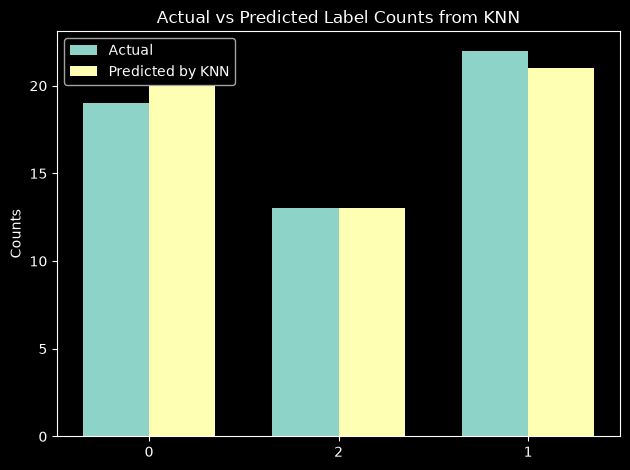

In [18]:
# Analisis untuk hasil yang diberikan dari modelKNN
labels = y_test.unique()
x = np.arange(len(labels)) # pengaturan lokasi dari label
width = 0.35 # pengaturan lebar dari grafik batang

# Menghitung jumlah kemunculan dari setiap kelas dalam y_test dan y_predKNN
y_test_counts = y_test.value_counts().sort_index()
y_predKNN_counts = pd.Series(y_predKNN).value_counts().sort_index()

# Memastikan kedua seri memiliki jumlah untuk semua label, dan mengisi yang
# kosong dengan nilai 0
y_test_counts = y_test_counts.reindex(labels, fill_value=0)
y_predKNN_counts = y_predKNN_counts.reindex(labels, fill_value=0)

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y_test_counts, width, label='Actual')
rects2 = ax.bar(x + width/2, y_predKNN_counts, width, label='Predicted by KNN')

ax.set_ylabel('Counts')
ax.set_title('Actual vs Predicted Label Counts from KNN')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.show()

## K-Nearest Neighbor
*Confusion matrix* KNN menunjukkan konsentrasi prediksi pada diagonal utama, dan grafik *Actual vs Predicted* memperlihatkan tinggi batang prediksi yang hampir setara dengan batang aktual pada ketiga kelas. Temuan ini mengindikasikan bahwa KNN menghasilkan prediksi yang akurat sekaligus seimbang, tanpa kecenderungan bias terhadap kelas tertentu. Kinerja tersebut konsisten dengan karakteristik dataset wine yang kelas-kelasnya terpisah relatif baik dalam ruang fitur ternormalisasi, sehingga KNN menjadi model yang paling diuntungkan oleh tahap normalisasi.  
Secara kuantitatif, dari 54 sampel uji hanya satu sampel kelas 1 yang keliru terprediksi sebagai kelas 0, sedangkan kelas 2 diprediksi sempurna dengan precision, recall, dan f1-score sebesar 1.00. Distribusi prediksi (20, 21, 13) juga sangat dekat dengan distribusi aktual (19, 22, 13), menegaskan tidak adanya bias sistematis pada model.  


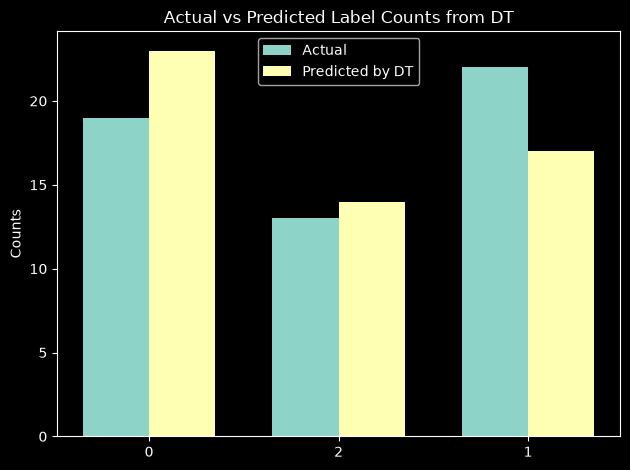

In [19]:
# Analisis untuk hasil yang diberikan dari modelDT
labels = y_test.unique()
x = np.arange(len(labels)) # pengaturan lokasi dari label
width = 0.35 # pengaturan lebar dari grafik batang

# Menghitung jumlah kemunculan dari setiap kelas dalam y_test dan y_predDT
y_test_counts = y_test.value_counts().sort_index()
y_predDT_counts = pd.Series(y_predDT).value_counts().sort_index()

# Memastikan kedua seri memiliki jumlah untuk semua label, dan mengisi yang
# kosong dengan nilai 0
y_test_counts = y_test_counts.reindex(labels, fill_value=0)
y_predDT_counts = y_predDT_counts.reindex(labels, fill_value=0)

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y_test_counts, width, label='Actual')
rects2 = ax.bar(x + width/2, y_predDT_counts, width, label='Predicted by DT')

ax.set_ylabel('Counts')
ax.set_title('Actual vs Predicted Label Counts from DT')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.show()

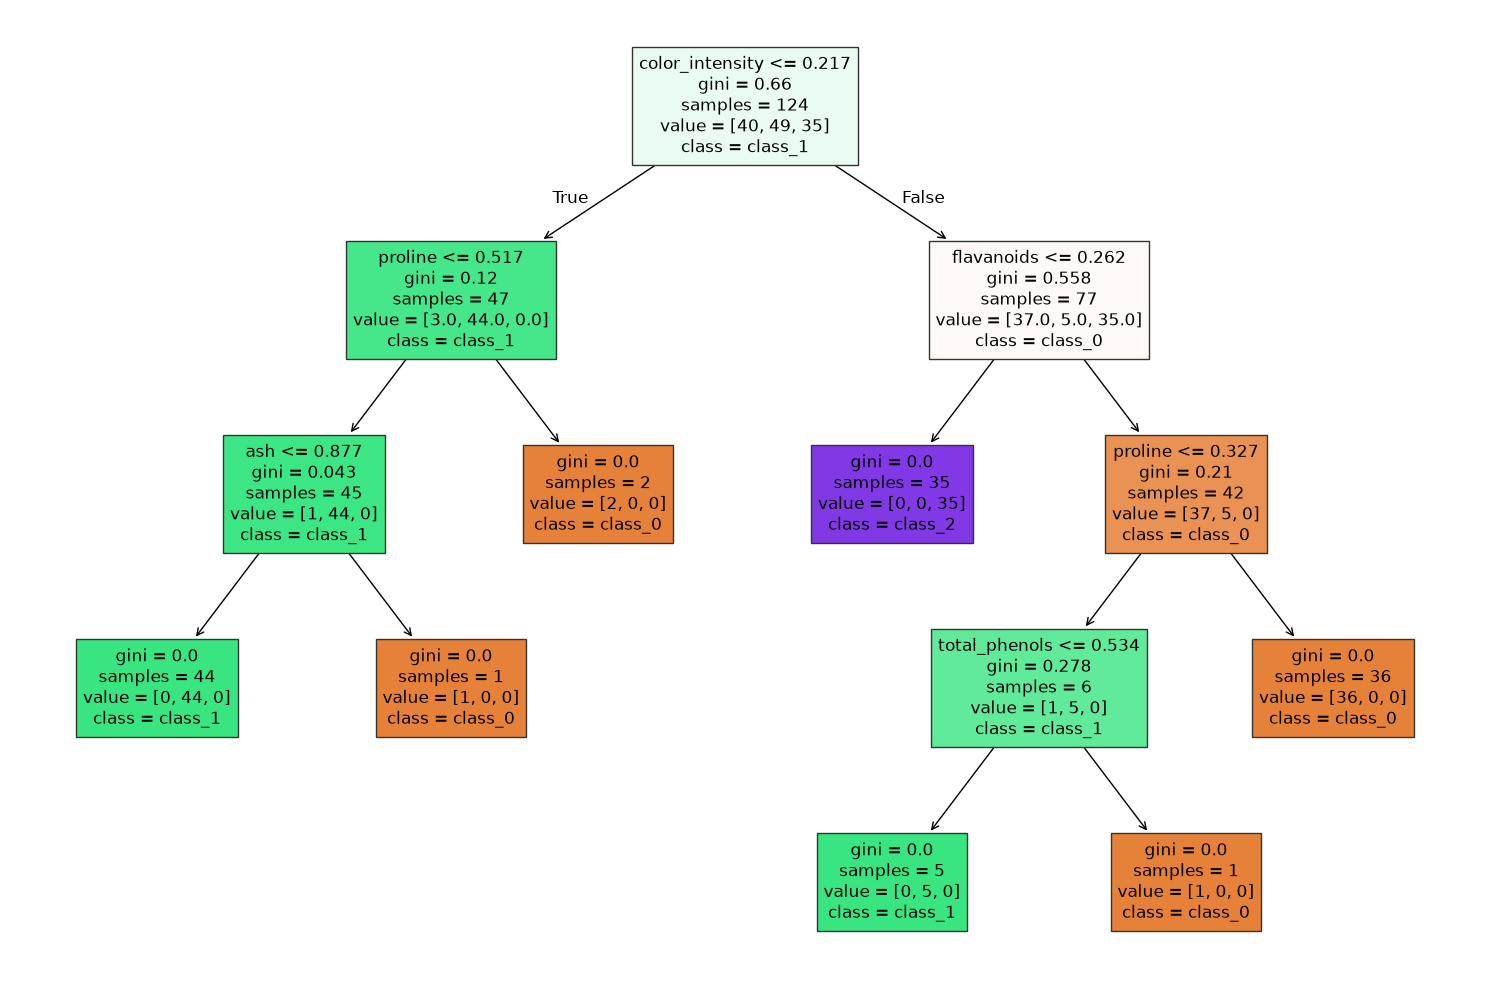

In [20]:
with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(15, 10), facecolor="white")
    ax.set_facecolor("white")

    nodes = tree.plot_tree(
        modelDT,
        feature_names=dataset["feature_names"],
        class_names=dataset["target_names"],
        filled=True,
        ax=ax,
    )

    for node in nodes:
        node.set_color("black")
        patch = node.get_bbox_patch()
        if patch is not None:
            patch.set_edgecolor("#333333")

    plt.tight_layout()
    plt.show()

## Decision Tree
Visualisasi pohon menunjukkan bahwa root node menggunakan aturan `color_intensity <= 0.217` dengan 124 sampel, yang menegaskan bahwa `color_intensity` merupakan fitur dengan daya pisah tertinggi. Kelas 2 terisolasi secara murni pada cabang kanan, sedangkan kelas 0 dan kelas 1 memerlukan percabangan yang lebih dalam (melibatkan `proline`, `ash`, dan `malic_acid`), mengindikasikan bahwa kedua kelas tersebut memiliki kemiripan karakteristik kimia yang lebih tinggi. Seluruh daun bernilai Gini = 0, yang berarti akurasi latih mencapai 100%; kondisi ini merupakan indikasi *overfitting*, sebab model cenderung menghafal data latih, termasuk sampel tunggal pada beberapa daun. Hal ini tercermin pada confusion matrix uji yang memuat tujuh kesalahan: lima sampel kelas 1 terprediksi sebagai kelas 0, satu sampel kelas 0 terprediksi sebagai kelas 1, dan satu sampel kelas 1 terprediksi sebagai kelas 2; dengan demikian enam dari tujuh kesalahan terjadi pada pasangan kelas 0 dan 1. Akibatnya, recall kelas 1 menurun menjadi 0.73 dan precision kelas 0 menjadi 0.78. Kesenjangan sebesar 13 poin persentase antara akurasi latih (100%) dan akurasi uji (87%) merupakan konfirmasi empiris terjadinya overfitting.  

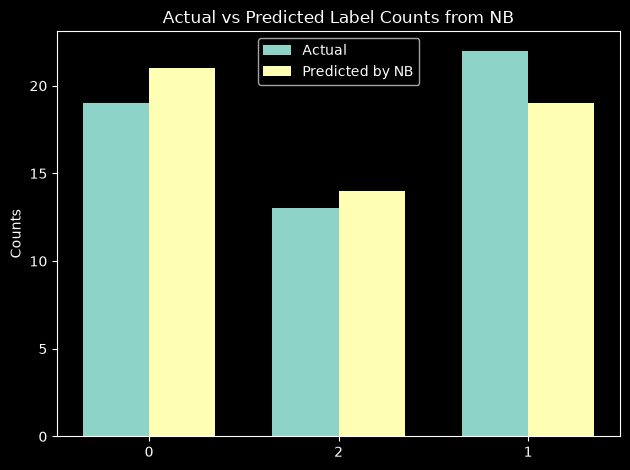

In [21]:
# Analisis untuk hasil yang diberikan dari modelNB
labels = y_test.unique()
x = np.arange(len(labels)) # pengaturan lokasi dari label
width = 0.35 # pengaturan lebar dari grafik batang

# Menghitung jumlah kemunculan dari setiap kelas dalam y_test dan y_predNB
y_test_counts = y_test.value_counts().sort_index()
y_predNB_counts = pd.Series(y_predNB).value_counts().sort_index()

# Memastikan kedua seri memiliki jumlah untuk semua label, dan mengisi yang
# kosong dengan nilai 0
y_test_counts = y_test_counts.reindex(labels, fill_value=0)
y_predNB_counts = y_predNB_counts.reindex(labels, fill_value=0)

fig, ax = plt.subplots()
rects1 = ax.bar(x - width/2, y_test_counts, width, label='Actual')
rects2 = ax.bar(x + width/2, y_predNB_counts, width, label='Predicted by NB')

ax.set_ylabel('Counts')
ax.set_title('Actual vs Predicted Label Counts from NB')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.show()

In [22]:
# Menampilkan beberapa parameter yang dihasilkan dari pelatihan modelNB
print("Varians dari setiap fitur pada setiap kelas:")
print(modelNB.var_)
print("\nMean dari setiap fitur pada setiap kelas:")
print(modelNB.theta_)

Varians dari setiap fitur pada setiap kelas:
[[0.01461157 0.01966651 0.01574387 0.01768186 0.01126529 0.01611712
  0.00771155 0.01642377 0.01771067 0.01214072 0.00843244 0.01764333
  0.02298298]
 [0.02282168 0.03404014 0.02788854 0.0336155  0.04088866 0.02639526
  0.01438521 0.04647257 0.04260036 0.00429426 0.02976924 0.0295189
  0.01300407]
 [0.01619552 0.05142655 0.00980516 0.01402045 0.0144001  0.01132593
  0.00353279 0.0543373  0.01242834 0.03782161 0.00816273 0.00899752
  0.0060916 ]]

Mean dari setiap fitur pada setiap kelas:
[[0.70842105 0.25568182 0.57459893 0.3132732  0.37527174 0.63887931
  0.5596519  0.29481132 0.47996845 0.3615401  0.47947154 0.6981685
  0.59802068]
 [0.33066595 0.23860611 0.47113391 0.50568062 0.28881988 0.4190007
  0.34762766 0.43819792 0.39992275 0.14163823 0.47064875 0.5610376
  0.18042738]
 [0.54834586 0.52461886 0.5842628  0.5640648  0.32546584 0.24502463
  0.09168174 0.61563342 0.23551149 0.51301804 0.16376307 0.1451596
  0.24852252]]


## Naive Bayes
Parameter `theta_` (mean) dan `var_` (varians) yang tercetak berada pada skala 0–1, konsisten dengan fakta bahwa model dilatih pada data yang telah dinormalisasi; hal ini membuktikan bahwa parameter model merefleksikan bentuk data masukan. Mean merepresentasikan profil pusat setiap kelas, sedangkan varians merepresentasikan toleransi sebaran fitur, yang bersama-sama menentukan likelihood pada proses prediksi. Meskipun asumsi independensi antar fitur secara teoretis tidak terpenuhi pada data kimia anggur yang berkorelasi, kinerja NB tetap kompetitif, sehingga menegaskan robustness algoritma ini sebagai model baseline yang efisien.  
Kesalahan prediksi NB seluruhnya melibatkan kelas 1, yaitu dua sampel kelas 1 yang terprediksi sebagai kelas 0 dan satu sampel kelas 1 yang terprediksi sebagai kelas 2, sehingga recall kelas 1 menurun menjadi 0.86 sementara kelas 0 dan kelas 2 mencapai recall 1.00. Menariknya, parameter `theta_` menunjukkan bahwa rata-rata ternormalisasi fitur color_intensity (indeks kolom 9) berbeda jelas antar kelas (0.36 pada kelas 0, 0.14 pada kelas 1, dan 0.51 pada kelas 2) dengan varians kelas 1 yang sangat kecil (0.0043); temuan ini konsisten dengan posisi color_intensity sebagai root split pada pohon keputusan, dan menjelaskan mengapa kedua model sama-sama mampu mengisolasi kelas 2 dengan sempurna.  

# Analisis Perbandingan Model

| Aspek | KNN | Decision Tree | Naive Bayes |
|---|---|---|---|
| **Akurasi Uji** | 0.98 (98%) | 0.87 (87%) | 0.94 (94%) |
| **Total Kesalahan (dari 54)** | 1 sampel | 7 sampel | 3 sampel |
| **Hasil Pembelajaran** | Penyimpanan data latih | Aturan IF-THEN (Pohon) | Mean ($\theta$) & Varians ($\sigma^2$) |
| **Kelebihan Empiris** | Akurasi tertinggi, minim bias | Logika klasifikasi transparan | Sangat cepat, stabil, seimbang |
| **Kelemahan Empiris** | Komputasi prediksi berat | Overfitting (Gini daun = 0) | Asumsi independensi fitur |
| **Sensitivitas Normalisasi** | Sangat Tinggi | Tidak Signifikan | Rendah |

Berdasarkan luaran yang disajikan, dapat dikemukakan tiga analisis perbandingan sebagai berikut:
1. *Confusion matrix* dan *classification report* mengukur ketepatan prediksi per sampel, sedangkan grafik batang mengukur keseimbangan distribusi prediksi; keduanya bersifat komplementer dan harus diinterpretasikan secara bersamaan, karena distribusi prediksi yang seimbang tidak serta-merta menjamin ketepatan per sampel.  
2. KNN dan NB cenderung unggul dari segi akurasi pada dataset ini, sedangkan DT unggul dari segi interpretabilitas karena seluruh logika keputusannya dapat diaudit secara visual; dengan demikian, pemilihan model perlu mempertimbangkan konteks kebutuhan aplikasi.  
3. Pola kesalahan DT terkonsentrasi pada pasangan kelas yang sulit dipisahkan (enam dari tujuh kesalahan terjadi antara kelas 0 dan 1), sedangkan kesalahan KNN dan NB tersebar pada sampel yang berada di wilayah tumpang tindih antar klaster kelas.  
Dan pada tabel, sel Kelemahan Empiris DT bisa ditambah: "Overfitting (Gini daun = 0); akurasi uji terendah.

# Kesimpulan
1. Alur kerja modul (preparation, definition, training, testing, analysis) merepresentasikan pipeline standar *supervised learning*, di mana tahap normalisasi dan pembagian data memberikan pengaruh paling signifikan terhadap validitas evaluasi.
2. Luaran setiap model mencerminkan karakteristik algoritmiknya: KNN stabil dan akurat namun bersifat *black-box*, DT interpretable namun rentan overfitting sebagaimana ditunjukkan oleh daun-daun murni, serta NB efisien namun bertumpu pada asumsi probabilistik yang kuat.
3. Evaluasi model tidak cukup didasarkan pada satu metrik tunggal; integrasi antara *confusion matrix*, *classification report*, dan visualisasi distribusi prediksi memberikan pemahaman yang lebih komprehensif terhadap perilaku masing-masing algoritma.
4. Sebagai rekomendasi praktis, KNN dapat direkomendasikan sebagai model utama untuk dataset wine ternormalisasi; DT memerlukan mekanisme regularisasi seperti pembatasan kedalaman (`max_depth`) atau minimum sampel per daun (`min_samples_leaf`) untuk memitigasi overfitting; sedangkan NB tetap layak digunakan sebagai baseline yang cepat dan stabil pada tahap awal pengembangan model.